In [1]:
# Imports
import tensorflow as tf

from tensorflow.keras.preprocessing import image_dataset_from_directory

# Layers for CNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Rescaling

from keras.callbacks import EarlyStopping

import numpy as np

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [3]:
# Get images (zip with the two class folders)
!unzip -q /content/data/OASIS_DSC599_Dataset_BinaryChange.zip

In [4]:
seed = 42

# Change?
image_size = (224, 224)
batch_size = 32

# Names of the two class folders: label 0, then label 1
classes = ['Demented', 'Non_Demented']

# Folder that holds the two class folders
data_path = '/content/OASIS_DSC599_Dataset_BinaryChange/Training'

# 70% of the images for training, 30% held out
training_dataset, validation_dataset = image_dataset_from_directory(data_path,
                                                class_names = classes,
                                                image_size = image_size,
                                                batch_size = batch_size,
                                                seed = seed,
                                                shuffle = True,
                                                validation_split = 0.3,
                                                subset = 'both',
                                                label_mode = 'int')

# Split the held out images in half: validation and testing
half = validation_dataset.cardinality() // 2
testing_dataset = validation_dataset.skip(half)
validation_dataset = validation_dataset.take(half)

Found 28703 files belonging to 2 classes.
Using 20093 files for training.
Using 8610 files for validation.


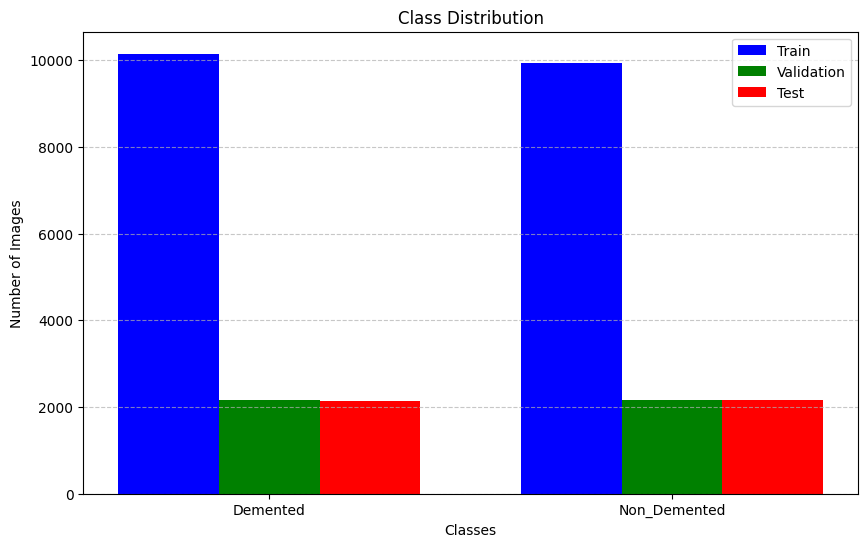

In [5]:
# Distribution of classes

def count_classes(dataset):
  class_counts = np.zeros(len(classes))
  for images, labels in dataset:
      for idx in labels.numpy():
          class_counts[idx] += 1
  return class_counts

train_counts = count_classes(training_dataset)
val_counts = count_classes(validation_dataset)
test_counts = count_classes(testing_dataset)

bar_width = 0.25

# Set position of bars on X axis
r1 = np.arange(len(classes))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]

plt.figure(figsize=(10,6))
plt.bar(r1, train_counts, color = 'blue', width = bar_width, label = 'Train')
plt.bar(r2, val_counts, color = 'green', width = bar_width, label = 'Validation')
plt.bar(r3, test_counts, color = 'red', width = bar_width, label = 'Test')
plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Class Distribution')
plt.xticks([r + bar_width for r in range(len(classes))], classes)
plt.legend()
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)

plt.show()

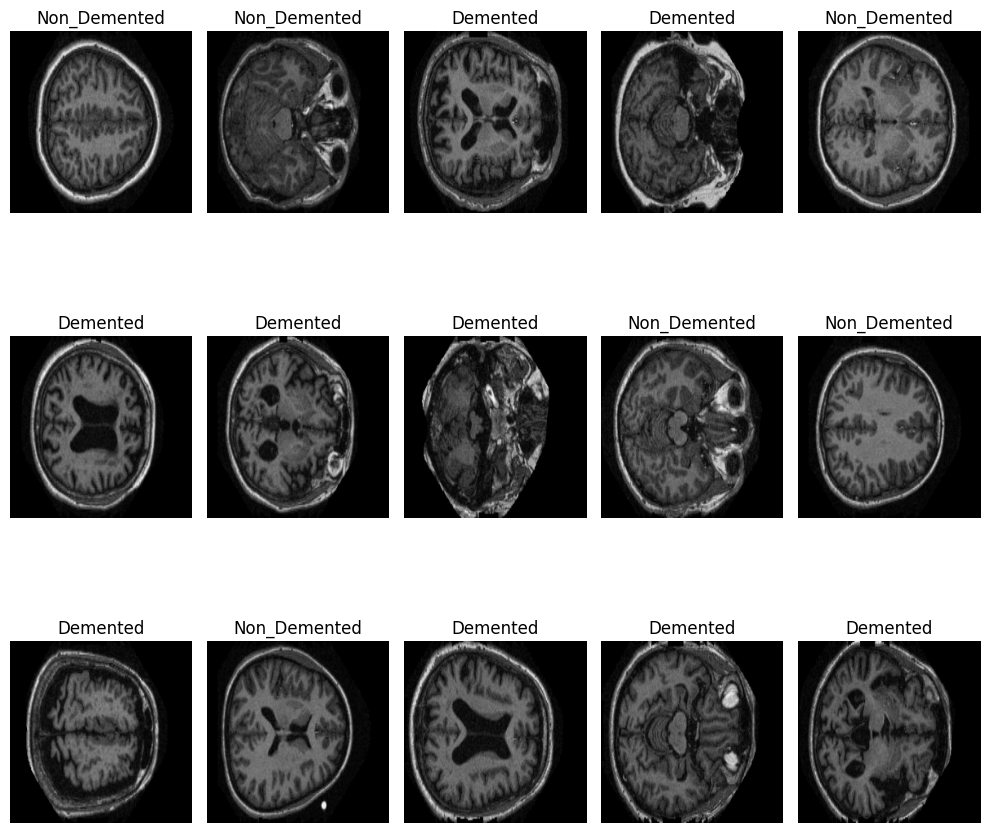

In [6]:
# Visualize some images

images, labels = next(iter(training_dataset))

# Change as needed, adjust grid below accordingly
num_images = 15

plt.figure(figsize = (10, 10))

for i in range(num_images):
  # 3x5 grid of the images
  ax = plt.subplot(3, 5, i + 1)
  plt.imshow(images[i].numpy().astype("uint8"))
  label_idx = labels[i].numpy()
  plt.title(classes[label_idx])
  plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Define model architecture
model = Sequential([
  Rescaling(1./255, input_shape = (224, 224, 3)),

  # Convolutional blocks. No bias, so the black background gives zero
  # activation and cannot show up in the class activation map
  Conv2D(32, (3, 3), activation = 'relu', padding = 'same', use_bias = False),
  MaxPooling2D(2, 2),

  Conv2D(64, (3, 3), activation = 'relu', padding = 'same', use_bias = False),
  MaxPooling2D(2, 2),

  Conv2D(128, (3, 3), activation = 'relu', padding = 'same', use_bias = False),
  MaxPooling2D(2, 2),

  Conv2D(256, (3, 3), activation = 'relu', padding = 'same', use_bias = False),

  # Global average pooling, then the probability of Dementia
  GlobalAveragePooling2D(),
  Dense(1, activation = 'sigmoid')
])

early_stop = EarlyStopping(monitor = 'val_loss',
                           patience = 2,
                           restore_best_weights = True)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,193 (1.48 MB)

 Trainable params: 388,193 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Model training

# Change as needed
epochs = 25
batch_size = 32

model.compile(optimizer = 'adam',
              loss = 'binary_crossentropy',
              metrics = ['accuracy']
              )

# Train model
history = model.fit(training_dataset,
                    validation_data = validation_dataset,
                    epochs = epochs,
                    batch_size = batch_size,
                    shuffle = True,
                    callbacks=[early_stop])

loss, accuracy = model.evaluate(testing_dataset)
print("Test loss: " + str(loss))
print("Test accuracy: " + str(accuracy))

Epoch 1/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 69s 88ms/step - accuracy: 0.5541 - loss: 0.6761 - val_accuracy: 0.7025 - val_loss: 0.6151
Epoch 2/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.7996 - loss: 0.4250 - val_accuracy: 0.8431 - val_loss: 0.3706
Epoch 3/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.8611 - loss: 0.3318 - val_accuracy: 0.8762 - val_loss: 0.3126
Epoch 4/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 42s 66ms/step - accuracy: 0.8829 - loss: 0.2860 - val_accuracy: 0.8988 - val_loss: 0.2558
Epoch 5/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.9041 - loss: 0.2378 - val_accuracy: 0.9155 - val_loss: 0.2143
Epoch 6/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.9277 - loss: 0.1866 - val_accuracy: 0.9273 - val_loss: 0.1815
Epoch 7/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.9428 - loss: 0.1464 - val_accuracy: 0.9558 - val_loss: 0.1194
Epoch 8/25
628/628 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.9611 - loss: 0.1058 - 

In [9]:
# Save model
model.save("project_model.h5")

In [10]:
# Load model
from tensorflow.keras.models import load_model
model = load_model("project_model.h5")

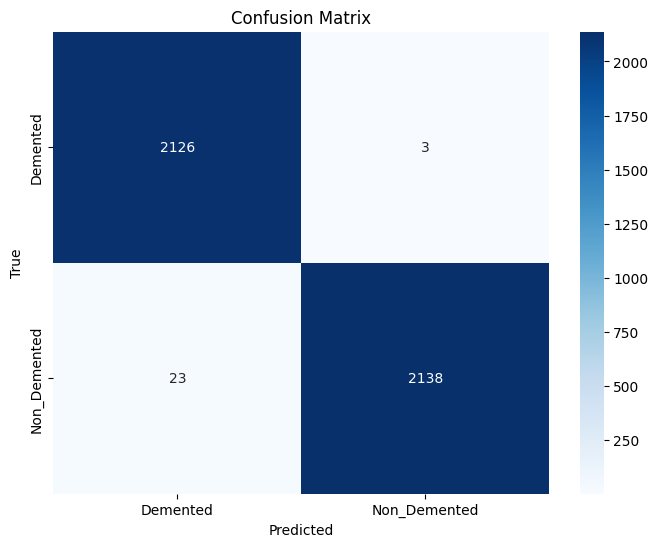

              precision    recall  f1-score   support

    Demented       0.99      1.00      0.99      2129
Non_Demented       1.00      0.99      0.99      2161

    accuracy                           0.99      4290
   macro avg       0.99      0.99      0.99      4290
weighted avg       0.99      0.99      0.99      4290



In [11]:
# Confusion matrix and classification report

import seaborn as sns

true_labels, pred_labels = [], []

for images, labels in testing_dataset:
  preds = model.predict(images, verbose=0)

  true_labels.extend(labels.numpy())
  pred_labels.extend((preds.flatten() > 0.5).astype(int))

true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)

cm = confusion_matrix(true_labels, pred_labels)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = classes,
            yticklabels = classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

plt.show()

print(classification_report(true_labels, pred_labels, target_names = classes))

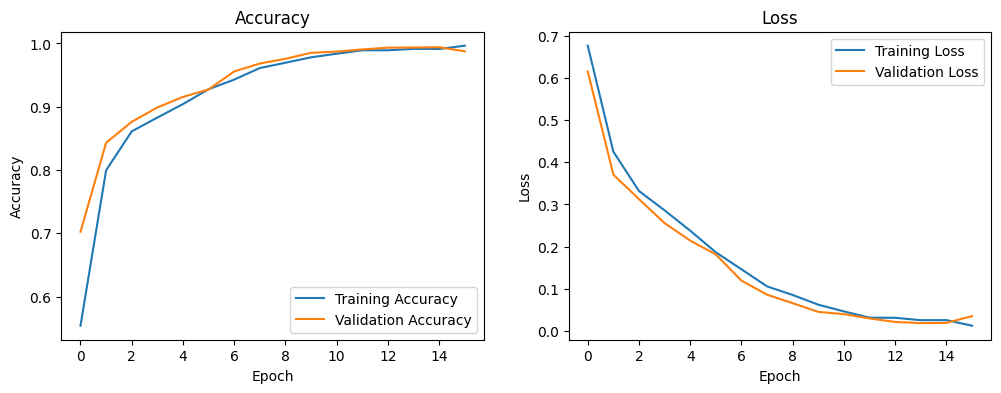

In [12]:
# Visualize model loss, accuracy
plt.figure(figsize=(12,4))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label = 'Training Accuracy')
plt.plot(history.history['val_accuracy'], label = 'Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label = 'Training Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


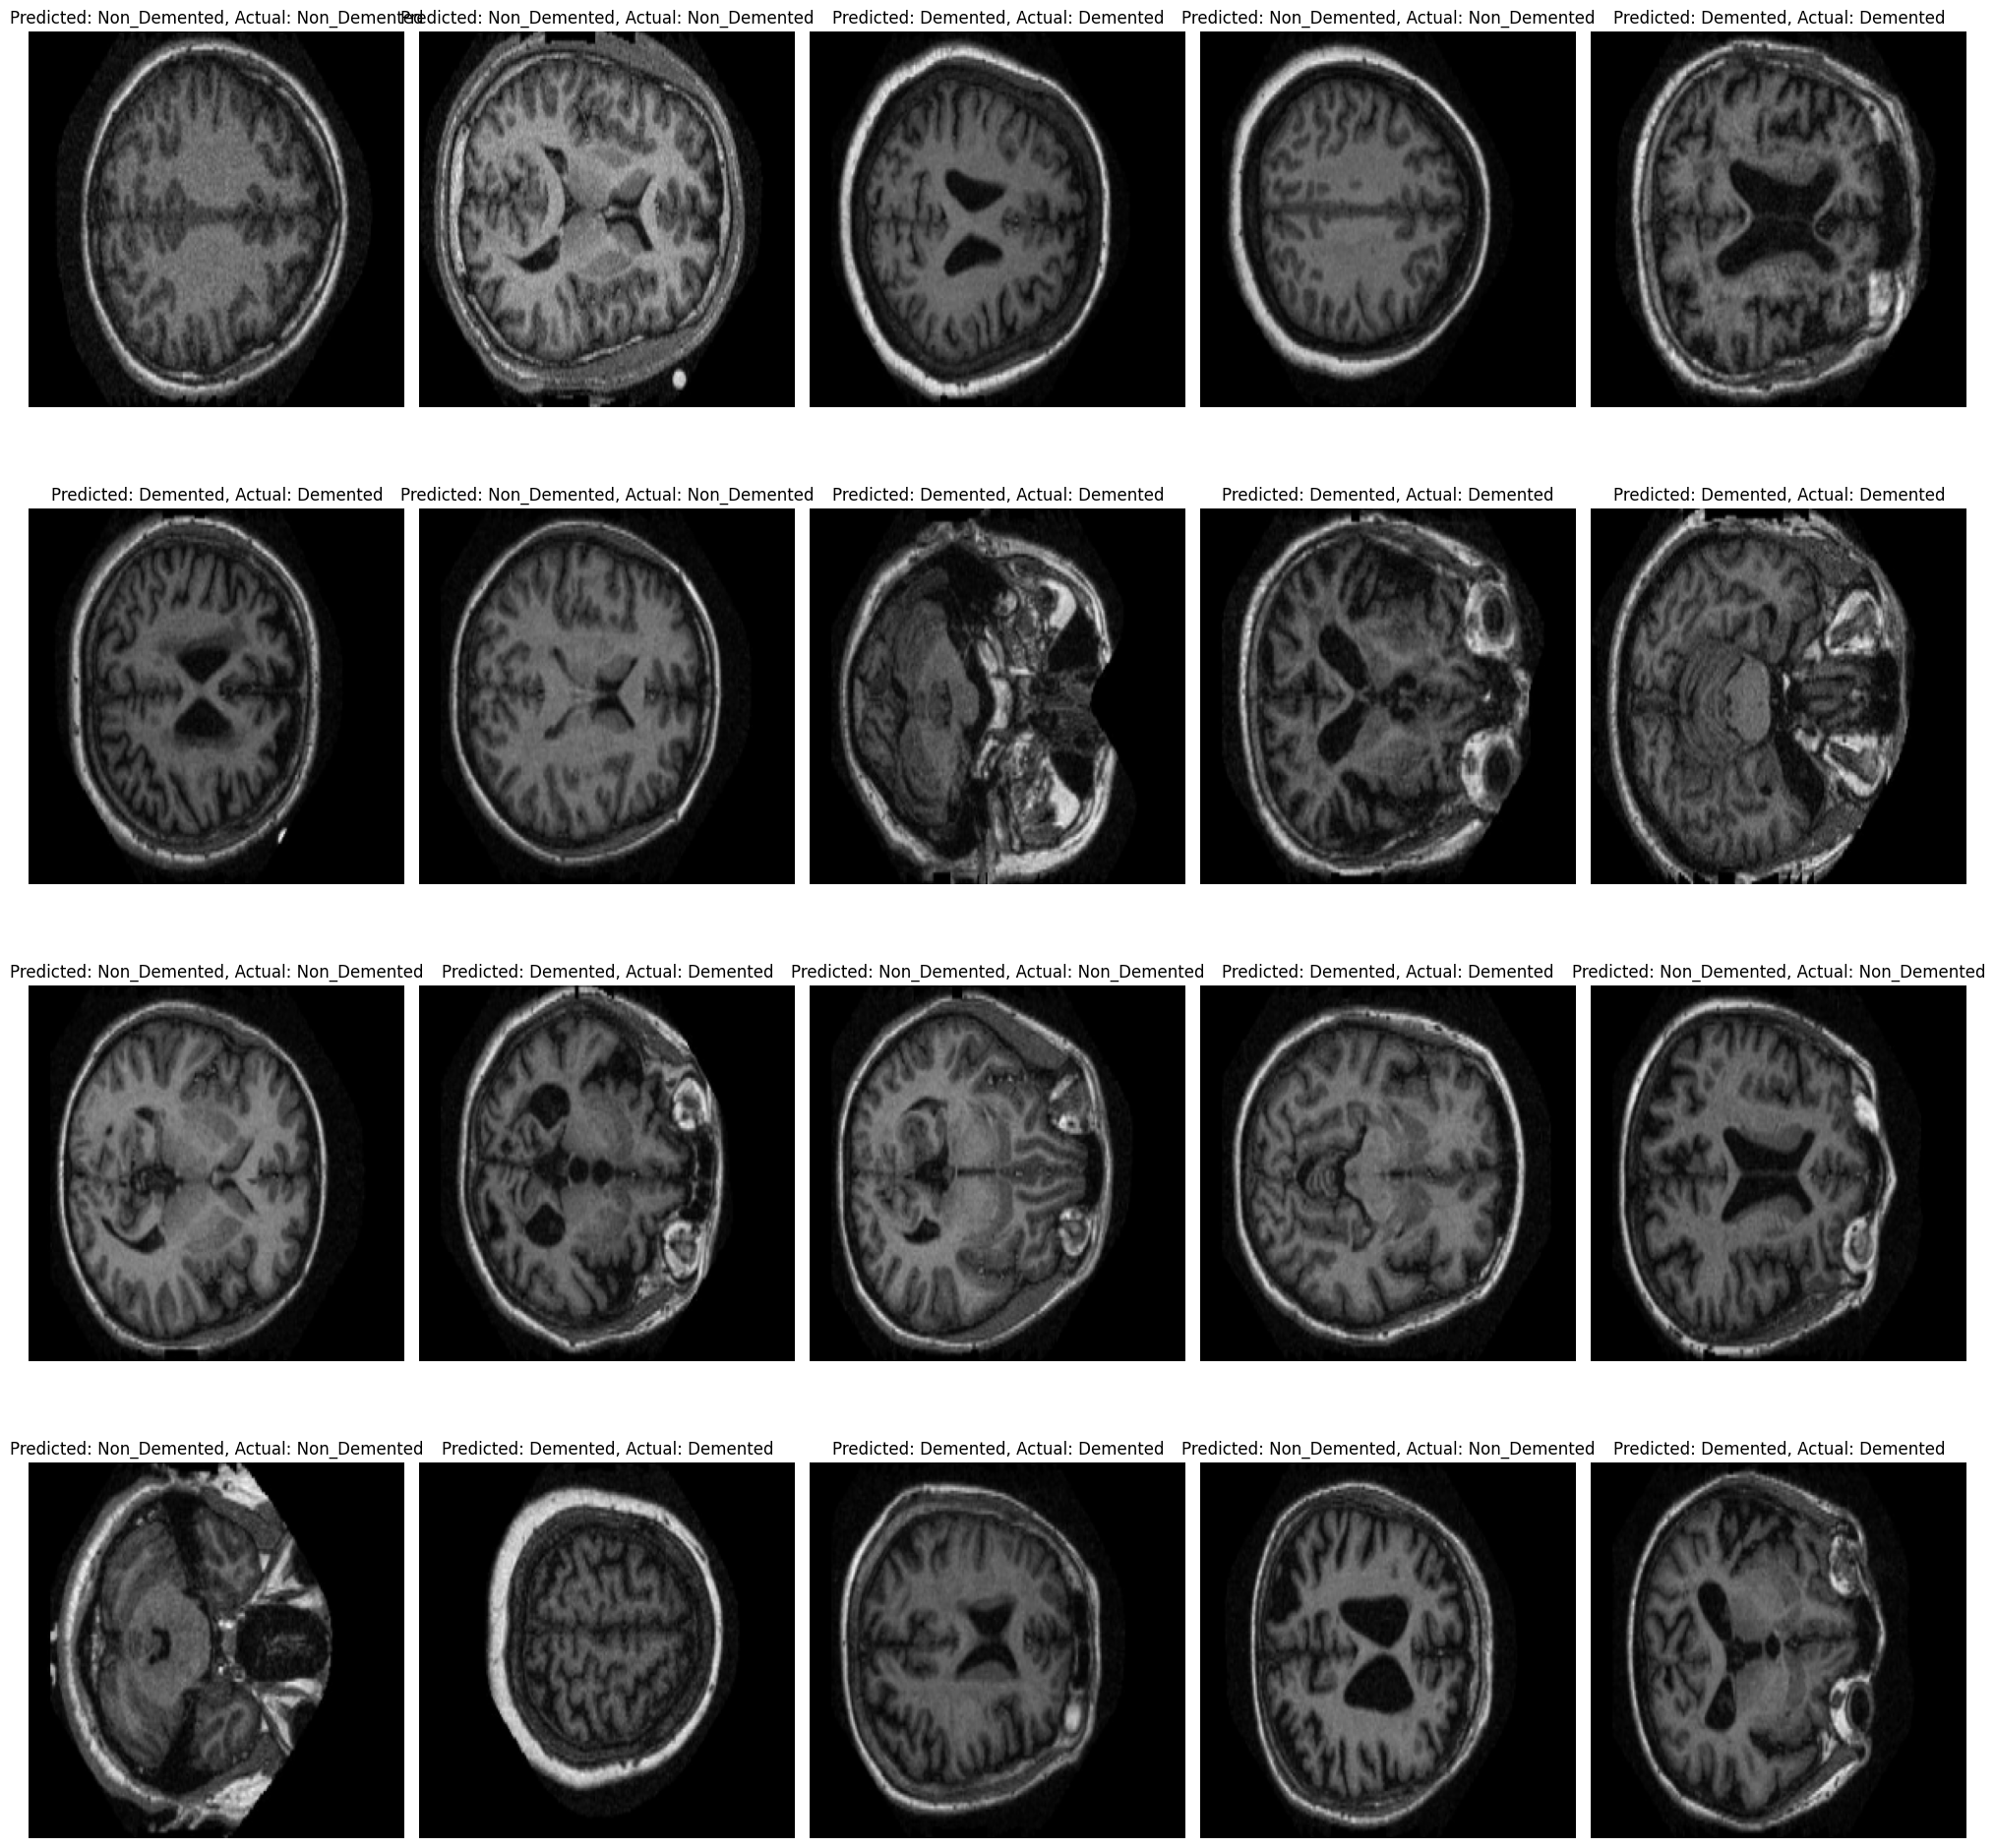

In [13]:
# Visualize model predictions vs ground truth labels

images, labels = next(iter(testing_dataset))

y_pred = model.predict(images)
y_pred = (y_pred.flatten() > 0.5).astype(int)

num_images = 20

plt.figure(figsize = (20, 20))

for i in range(num_images):
  # 3x5 grid of the images
  ax = plt.subplot(4, 5, i + 1)
  plt.imshow(images[i].numpy().astype("uint8"))
  label_idx = labels[i].numpy()
  plt.title(f'Predicted: {classes[y_pred[i]]}, Actual: {classes[label_idx]}')
  plt.axis("off")

plt.tight_layout()
plt.show()

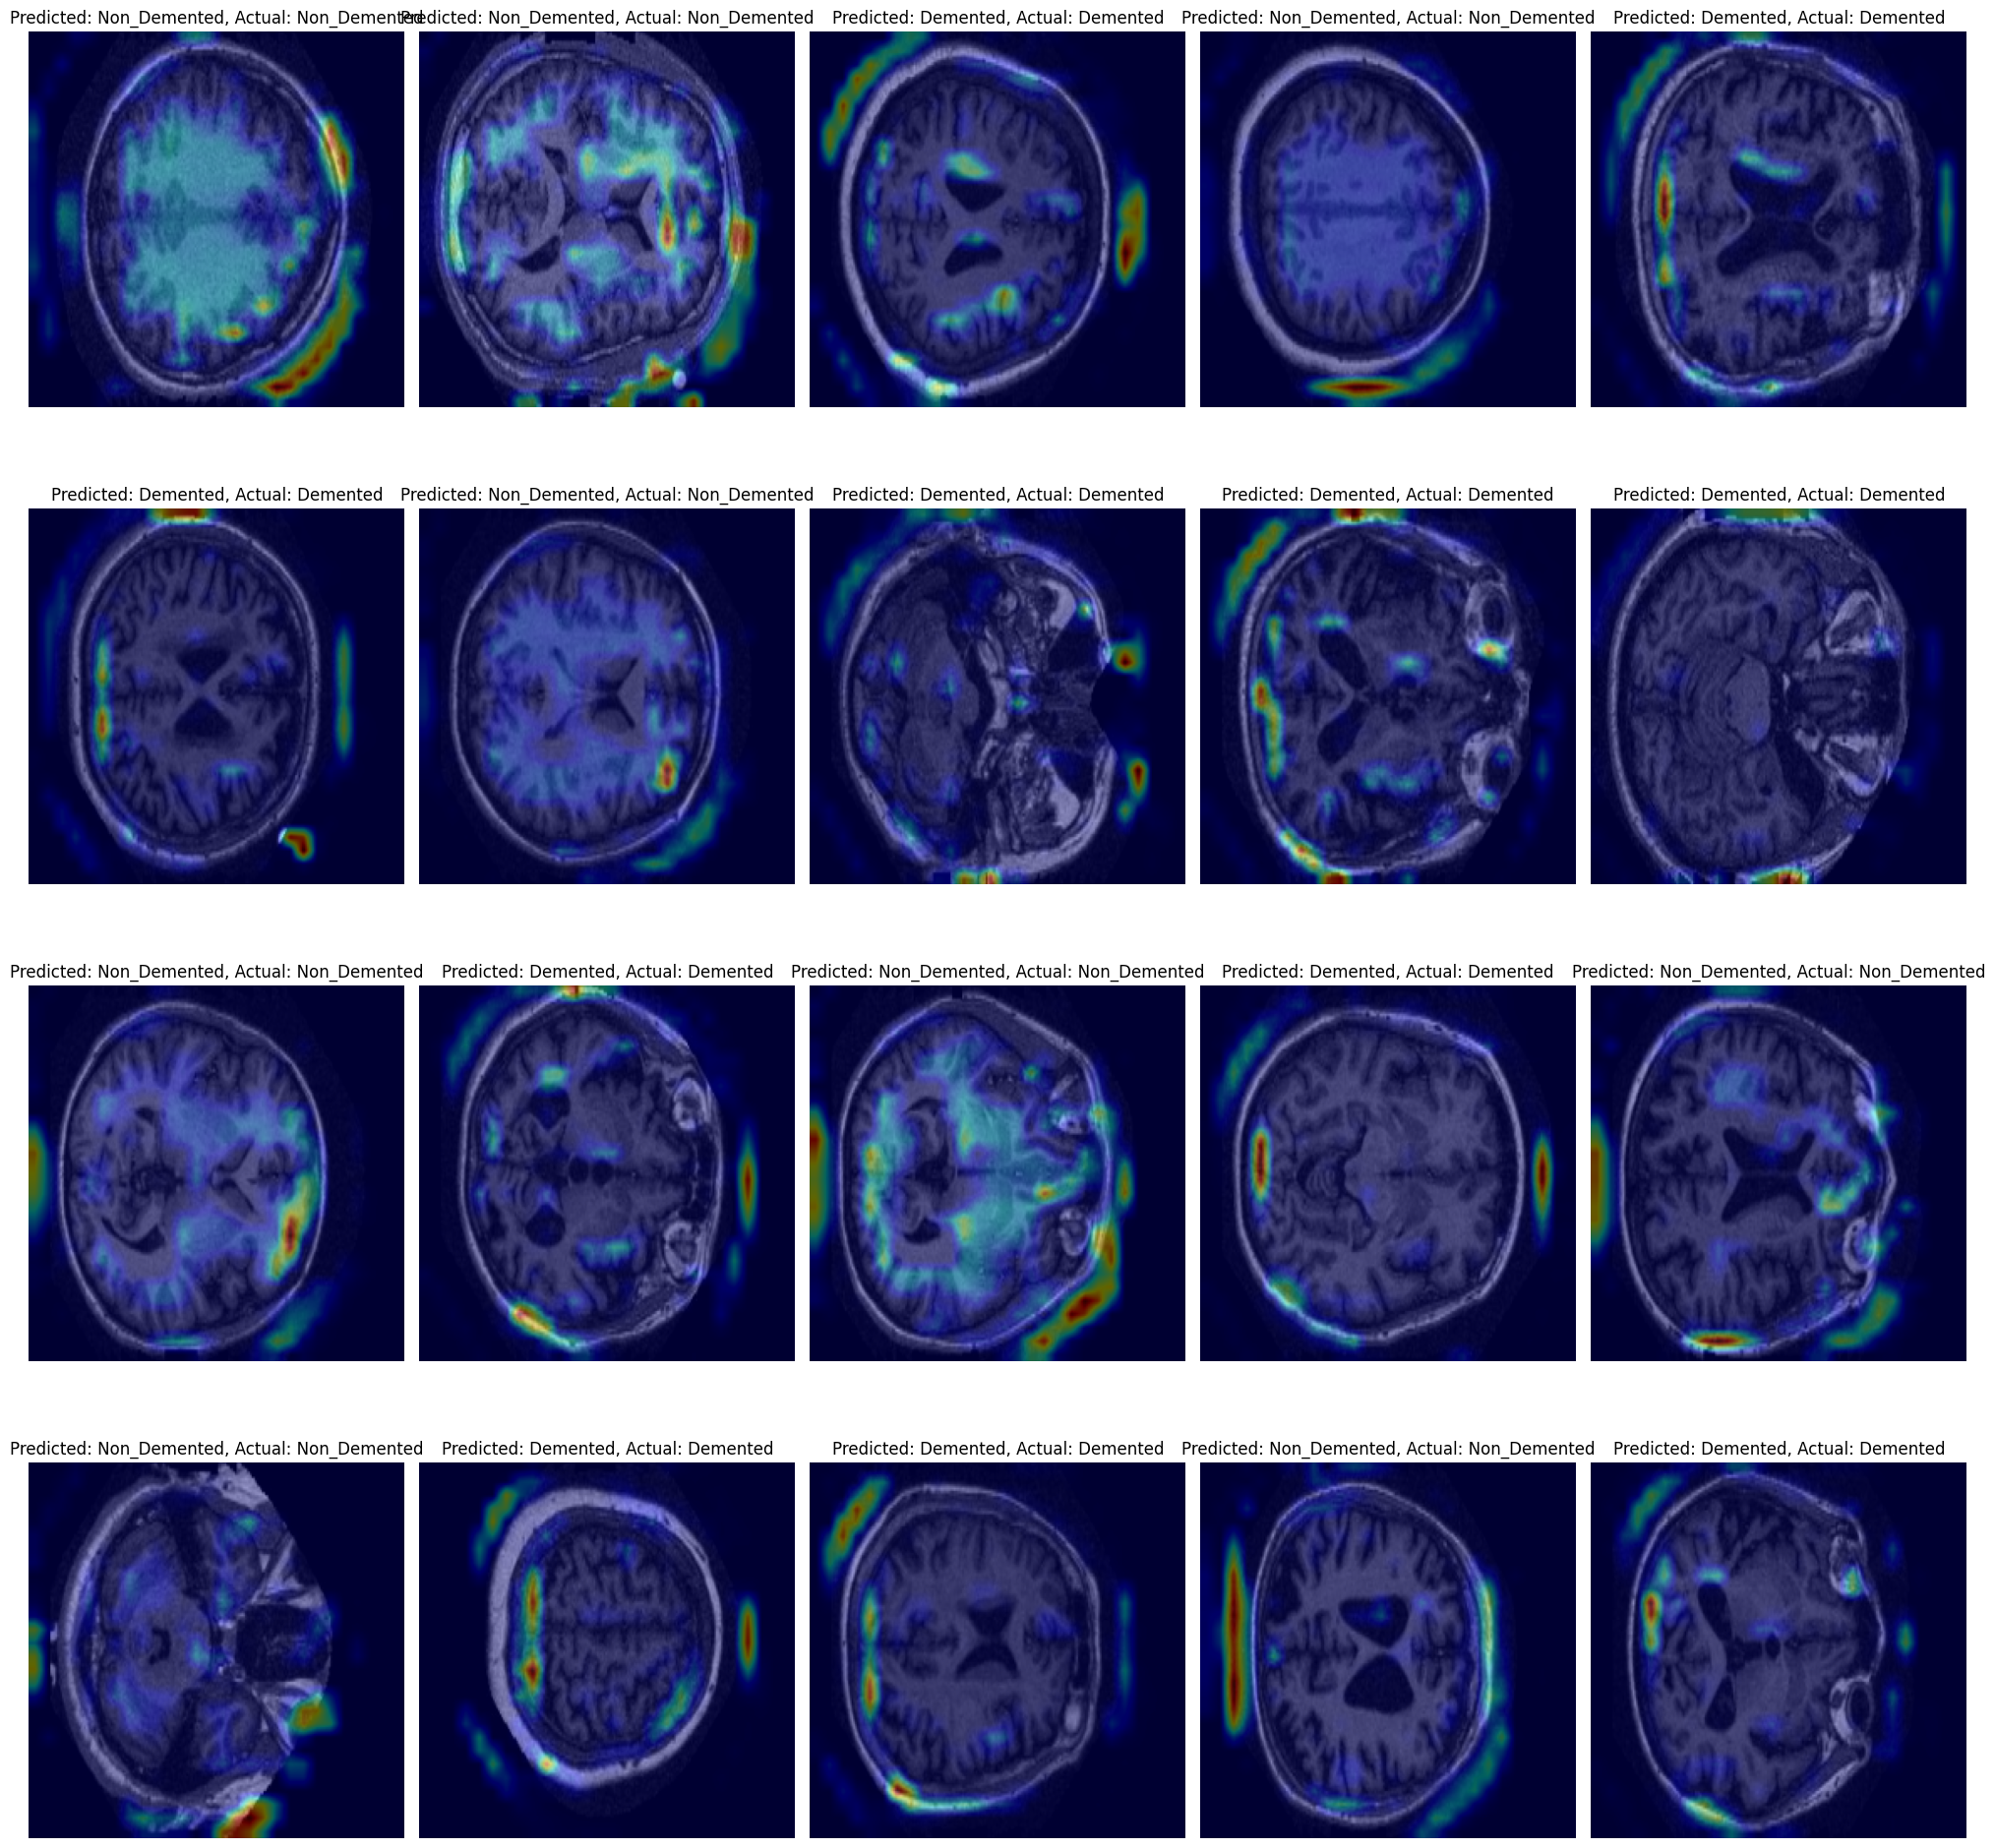

In [14]:
# Class activation map for the same images: feature maps of the last
# convolutional layer, weighted by the weights of the output layer
conv_output = Sequential(model.layers[:-2])(images)
cams = conv_output @ model.layers[-1].get_weights()[0]

# Keep what supports the predicted class (negative values support not Dementia)
cams = tf.nn.relu(tf.where(y_pred[:, None, None, None] == 1, cams, -cams))
cams = tf.image.resize(cams, image_size)

plt.figure(figsize = (20, 20))

for i in range(num_images):
  ax = plt.subplot(4, 5, i + 1)
  plt.imshow(images[i].numpy().astype("uint8"))
  plt.imshow(cams[i, :, :, 0], cmap = 'jet', alpha = 0.4)
  plt.title(f'Predicted: {classes[y_pred[i]]}, Actual: {classes[labels[i].numpy()]}')
  plt.axis("off")

plt.tight_layout()
plt.show()

In [2]:
!pip install -q --upgrade gdown
!gdown --folder https://drive.google.com/drive/folders/16JAUFq5YJI677ZL2xwEXwHLa_N8W8AUI -O /content/data

Retrieving folder contents
Processing file 1Nm_QMKGnhNJdAo8VEWrOm5SgCuE-iaYd OASIS_DSC599_Dataset_BinaryChange.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1Nm_QMKGnhNJdAo8VEWrOm5SgCuE-iaYd
From (redirected): https://drive.google.com/uc?id=1Nm_QMKGnhNJdAo8VEWrOm5SgCuE-iaYd&confirm=t&uuid=90456ed8-20cc-415f-ae16-ebe7f789a870
To: /content/data/OASIS_DSC599_Dataset_BinaryChange.zip
100% 586M/586M [00:15<00:00, 36.9MB/s]
Download completed
